# Student Performance Data Analysis

## 1. Dataset Loading and Initial Exploration

This project analyzes student academic performance
using descriptive statistics and linear regression.

Dataset: Student Performance (UCI Machine Learning Repository).

In [1]:
import pandas as pd

df = pd.read_csv("data/student-mat.csv", sep=";")

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10



## 2. Research Question and Hypotheses

### Research Question

Is there a statistically significant relationship between students' previous grades (G1 and G2) and their final grade (G3)?

### Variables

- **G1:** First period grade (Independent Variable)
- **G2:** Second period grade (Independent Variable)
- **G3:** Final grade (Dependent Variable)

### Hypotheses

**H0 (Null Hypothesis):**
The regression coefficients of G1 and G2 are both equal to zero.

**H1 (Alternative Hypothesis):**
At least one of the regression coefficients is different from zero.

**Significance Level:** alpha = 0.05

## 3. Stevens Measurement Scale Classification

Each variable is classified according to Stevens' four measurement scales:

- **Nominal:** Categories without a natural order.
- **Ordinal:** Categories with a meaningful order.
- **Interval:** Numerical values with meaningful differences.
- **Ratio:** Numerical values with a meaningful absolute zero.


In [2]:
stevens = {
    "Nominal": [
        "school", "sex", "address", "Pstatus",
        "Mjob", "Fjob", "reason", "guardian",
        "schoolsup", "famsup", "paid", "activities",
        "nursery", "higher", "internet", "romantic"
    ],

    "Ordinal": [
        "famsize", "Medu", "Fedu", "traveltime",
        "studytime", "failures", "famrel",
        "freetime", "goout", "Dalc", "Walc", "health"
    ],

    "Interval": [
        "G1", "G2", "G3"
    ],

    "Ratio": [
        "age", "absences"
    ]
}

classification = {
    column: scale
    for scale, columns in stevens.items()
    for column in columns
}

classification_table = pd.DataFrame({
    "Variable": df.columns,
    "Python Data Type": df.dtypes.astype(str).values,
    "Stevens Scale": [
        classification.get(col, "Unclassified")
        for col in df.columns
    ]
})

display(classification_table)

print("\nVariables by measurement scale:")
print(classification_table["Stevens Scale"].value_counts())

assert set(df.columns) == set(classification)

print("\nAll 33 variables have been classified!")


,Variable,Python Data Type,Stevens Scale
0,school,str,Nominal
1,sex,str,Nominal
2,age,int64,Ratio
3,address,str,Nominal
4,famsize,str,Ordinal
5,Pstatus,str,Nominal
6,Medu,int64,Ordinal
7,Fedu,int64,Ordinal
8,Mjob,str,Nominal
9,Fjob,str,Nominal



Variables by measurement scale:
Stevens Scale
Nominal     16
Ordinal     12
Interval     3
Ratio        2
Name: count, dtype: int64

All 33 variables have been classified!



## 4. Data Cleaning and Outlier Detection

This section evaluates the quality of the dataset.

The following checks are performed:

- Missing values
- Duplicate records
- Outlier detection using the IQR method

### Outlier Detection

The Interquartile Range (IQR) method is used:

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 * IQR

Upper Bound = Q3 + 1.5 * IQR

Outliers are reviewed before deciding whether to remove them.

The dataset contains valid extreme observations.
Therefore, all 395 records are retained for analysis.


In [3]:

print("=== MISSING VALUES ===")
print("Total missing values:", df.isnull().sum().sum())

print("\n=== DUPLICATES ===")
print("Total duplicates:", df.duplicated().sum())

print("\n=== OUTLIER DETECTION ===")

numeric_columns = ["age", "absences", "G1", "G2", "G3"]

outliers_summary = []

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outliers_summary.append({
        "Variable": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outliers": len(outliers)
    })

outliers_df = pd.DataFrame(outliers_summary)
display(outliers_df)

df_clean = df.copy()

print("\n=== FINAL DATASET ===")
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("Data unchanged:", df.equals(df_clean))


=== MISSING VALUES ===
Total missing values: 0

=== DUPLICATES ===
Total duplicates: 0

=== OUTLIER DETECTION ===


,Variable,Lower Bound,Upper Bound,Outliers
0,age,13.0,21.0,1
1,absences,-12.0,20.0,15
2,G1,0.5,20.5,0
3,G2,3.0,19.0,13
4,G3,-1.0,23.0,0



=== FINAL DATASET ===
Original shape: (395, 33)
Cleaned shape: (395, 33)
Data unchanged: True



## 5. Descriptive Statistics and Data Visualization

This section explores the statistical characteristics of student academic performance.

The analysis includes:

- Mean, median, and standard deviation
- Minimum and maximum values
- Variance and quartiles
- Histogram of final grades (G3)
- Scatter plot of G2 and G3
- Boxplot comparing G1, G2, and G3

The objective is to understand the distribution of grades, identify patterns, and explore potential relationships between variables.


In [4]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

columns = ["age", "absences", "G1", "G2", "G3"]

statistics = df_clean[columns].describe().T

statistics["median"] = df_clean[columns].median()
statistics["variance"] = df_clean[columns].var()

print("=== DESCRIPTIVE STATISTICS ===")
display(statistics.round(2))


=== DESCRIPTIVE STATISTICS ===


,count,mean,std,min,25%,50%,75%,max,median,variance
age,395.0,16.70,1.28,15.0,16.0,17.0,18.0,22.0,17.0,1.63
absences,395.0,5.71,8.00,0.0,0.0,4.0,8.0,75.0,4.0,64.05
G1,395.0,10.91,3.32,3.0,8.0,11.0,13.0,19.0,11.0,11.02
G2,395.0,10.71,3.76,0.0,9.0,11.0,13.0,19.0,11.0,14.15
G3,395.0,10.42,4.58,0.0,8.0,11.0,14.0,20.0,11.0,20.99


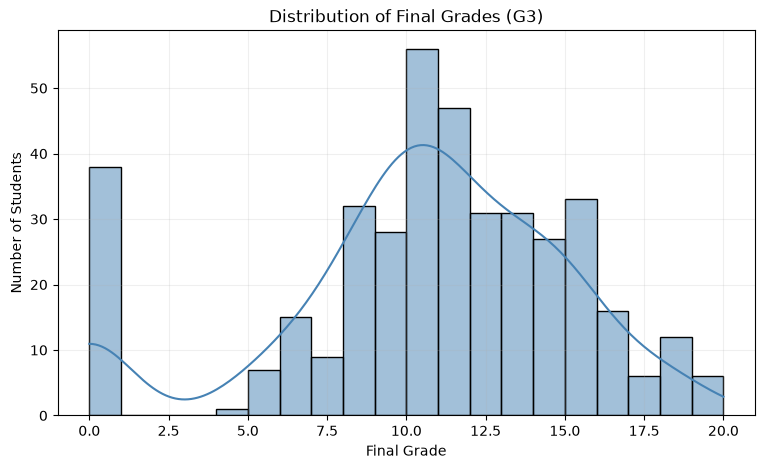

In [5]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="G3",
    bins=20,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Final Grades (G3)")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")
plt.grid(alpha=0.2)

plt.show()


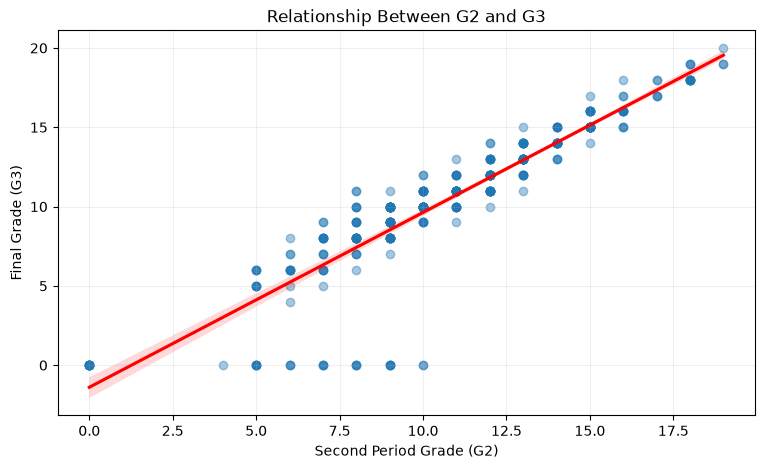

In [6]:

plt.figure(figsize=(9, 5))

sns.regplot(
    data=df_clean,
    x="G2",
    y="G3",
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"}
)

plt.title("Relationship Between G2 and G3")
plt.xlabel("Second Period Grade (G2)")
plt.ylabel("Final Grade (G3)")
plt.grid(alpha=0.2)

plt.show()


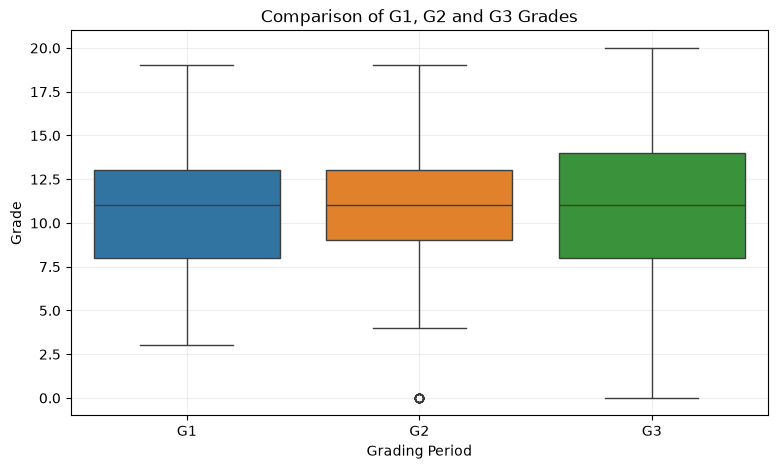

In [7]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean[["G1", "G2", "G3"]]
)

plt.title("Comparison of G1, G2 and G3 Grades")
plt.xlabel("Grading Period")
plt.ylabel("Grade")
plt.grid(alpha=0.2)

plt.show()



### Interpretation of Descriptive Statistics

The dataset contains 395 student records.

The average student age is 16.70 years, while the average number of absences is 5.71.

The average grades are:

- G1: 10.91
- G2: 10.71
- G3: 10.42

The results indicate a slight decrease in average grades from the first grading period to the final grade.

G3 has the highest standard deviation (4.58), indicating greater variability in final grades.

The scatter plot suggests a positive linear relationship between G2 and G3.

The boxplot allows comparison of grade distributions and identification of potential outliers.

These findings provide the foundation for correlation analysis and linear regression modeling.


## 6. Correlation Analysis

Pearson correlation measures how strongly two variables are linearly related, from -1 to +1.
We check it before regression to confirm that G1 and G2 are actually related to G3.

In [8]:
grades = df_clean[["G1", "G2", "G3"]]

correlation_matrix = grades.corr()

print("=== PEARSON CORRELATION MATRIX ===")
display(correlation_matrix.round(3))

=== PEARSON CORRELATION MATRIX ===


,G1,G2,G3
G1,1.000,0.852,0.801
G2,0.852,1.000,0.905
G3,0.801,0.905,1.000


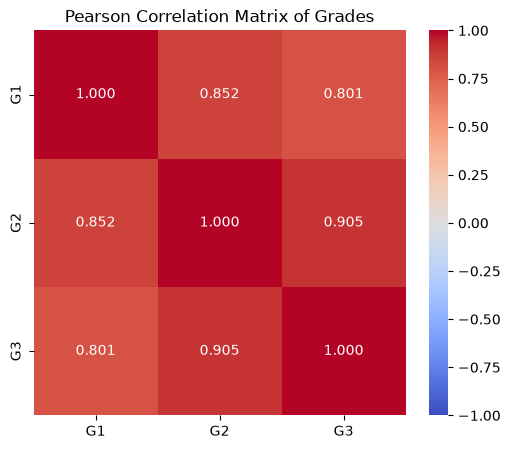

In [9]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".3f"
)

plt.title("Pearson Correlation Matrix of Grades")
plt.show()

### Interpretation of Correlation Analysis

All three grades are strongly and positively correlated.
The strongest relationship is between G2 and G3 (r = 0.905), so G2 is the best single predictor of the final grade.
G1 and G2 are also strongly correlated with each other (r = 0.852), which means they carry similar information.
Because of this, adding G1 to a model that already contains G2 is expected to improve it only slightly.

## 7. Simple Linear Regression (G2 → G3)

A simple linear regression model is built using the Ordinary Least Squares (OLS) method.

G2 (second period grade) is the independent variable and G3 (final grade) is the dependent variable.

Model: G3 = b0 + b1 × G2

In [10]:
import statsmodels.formula.api as smf

simple_model = smf.ols("G3 ~ G2", data=df_clean).fit()

print(simple_model.summary())

                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.819
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     1776.
Date:                Fri, 30 Oct 2026   Prob (F-statistic):          7.63e-148
Time:                        10:08:15   Log-Likelihood:                -823.83
No. Observations:                 395   AIC:                             1652.
Df Residuals:                     393   BIC:                             1660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.3928      0.297     -4.690      0.0

In [11]:
b0 = simple_model.params["Intercept"]
b1 = simple_model.params["G2"]

print("=== SIMPLE REGRESSION RESULTS ===")
print(f"Equation: G3 = {b0:.4f} + {b1:.4f} × G2")
print(f"R-squared: {simple_model.rsquared:.4f}")
print(f"Adjusted R-squared: {simple_model.rsquared_adj:.4f}")
print(f"p-value (G2): {simple_model.pvalues['G2']:.2e}")

=== SIMPLE REGRESSION RESULTS ===
Equation: G3 = -1.3928 + 1.1021 × G2
R-squared: 0.8188
Adjusted R-squared: 0.8183
p-value (G2): 7.63e-148


### Interpretation of Simple Regression

The estimated model is: G3 = -1.3928 + 1.1021 × G2.

Each additional point in G2 is associated with an increase of about 1.10 points in the predicted final grade.

The coefficient of G2 is statistically significant (p = 7.63e-148 < 0.05), so G2 is a significant predictor of G3.

R² = 0.8188, meaning G2 alone explains about 81.9% of the variation in final grades.

The intercept (-1.39) has no practical meaning, since a grade cannot be negative. It only positions the line.

## 8. Multiple Linear Regression (G1 + G2 → G3)

The model is extended with a second explanatory variable, so that G1 and G2 are used together.

This model tests the hypotheses from Section 2:

- **H0:** both coefficients are zero (b1 = b2 = 0)
- **H1:** at least one coefficient is different from zero

Model: G3 = b0 + b1 × G1 + b2 × G2

In [12]:
multiple_model = smf.ols("G3 ~ G1 + G2", data=df_clean).fit()

print(multiple_model.summary())

                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.822
Model:                            OLS   Adj. R-squared:                  0.821
Method:                 Least Squares   F-statistic:                     906.1
Date:                Fri, 30 Oct 2026   Prob (F-statistic):          1.01e-147
Time:                        10:08:15   Log-Likelihood:                -820.11
No. Observations:                 395   AIC:                             1646.
Df Residuals:                     392   BIC:                             1658.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.8300      0.335     -5.458      0.0

In [13]:
comparison = pd.DataFrame({
    "Simple (G2)": {
        "R-squared": simple_model.rsquared,
        "Adjusted R-squared": simple_model.rsquared_adj,
        "Coefficient G1": np.nan,
        "Coefficient G2": simple_model.params["G2"],
        "p-value G1": np.nan,
        "p-value G2": simple_model.pvalues["G2"],
        "F-test p-value": simple_model.f_pvalue
    },
    "Multiple (G1 + G2)": {
        "R-squared": multiple_model.rsquared,
        "Adjusted R-squared": multiple_model.rsquared_adj,
        "Coefficient G1": multiple_model.params["G1"],
        "Coefficient G2": multiple_model.params["G2"],
        "p-value G1": multiple_model.pvalues["G1"],
        "p-value G2": multiple_model.pvalues["G2"],
        "F-test p-value": multiple_model.f_pvalue
    }
})

print("=== MODEL COMPARISON ===")
display(comparison)

print(f"R-squared increase: {multiple_model.rsquared - simple_model.rsquared:.5f}")

=== MODEL COMPARISON ===


,Simple (G2),Multiple (G1 + G2)
R-squared,8.187861e-01,8.221632e-01
Adjusted R-squared,8.183250e-01,8.212559e-01
Coefficient G1,NaN,1.532686e-01
Coefficient G2,1.102112e+00,9.868668e-01
p-value G1,NaN,6.650666e-03
p-value G2,7.625719e-148,1.904883e-61
F-test p-value,7.625719e-148,1.009775e-147


R-squared increase: 0.00338


### Interpretation of Multiple Regression

The estimated model is: G3 = -1.8300 + 0.1533 × G1 + 0.9869 × G2.

Holding G2 constant, one more point in G1 is associated with about 0.15 more points in the predicted final grade.

Holding G1 constant, one more point in G2 is associated with about 0.99 more points in the predicted final grade.

Both coefficients are statistically significant (G1: p = 0.00665, G2: p = 1.90e-61).

The F-test is also significant (F = 906.13, p = 1.01e-147), so **H0 is rejected** at alpha = 0.05.

R² increases only from 0.8188 to 0.8222 (about 0.34 percentage points), and adjusted R² from 0.8183 to 0.8213.

G1 is significant, but its practical contribution is small. G1 and G2 are strongly correlated (r = 0.852), so most of the information in G1 is already contained in G2. This is also why the G2 coefficient falls from 1.10 to 0.99 once G1 is added.

## 9. Residual Analysis

A residual is the difference between the actual and the predicted grade: residual = G3 - predicted G3.

Residuals of the multiple regression model are examined to check how large the errors are and whether the OLS assumptions are reasonable. In a good model they should be centred on zero, show no pattern and be approximately normally distributed.

In [14]:
fitted_values = multiple_model.fittedvalues
residuals = multiple_model.resid

print("=== RESIDUAL STATISTICS ===")
print(f"Mean: {residuals.mean():.4f}")
print(f"Standard deviation: {residuals.std():.3f}")
print(f"MAE: {residuals.abs().mean():.3f}")
print(f"RMSE: {np.sqrt((residuals ** 2).mean()):.3f}")
print(f"Minimum: {residuals.min():.2f}")
print(f"Maximum: {residuals.max():.2f}")
print(f"Skewness: {residuals.skew():.2f}")

=== RESIDUAL STATISTICS ===
Mean: 0.0000
Standard deviation: 1.932
MAE: 1.138
RMSE: 1.930
Minimum: -9.57
Maximum: 3.71
Skewness: -2.65


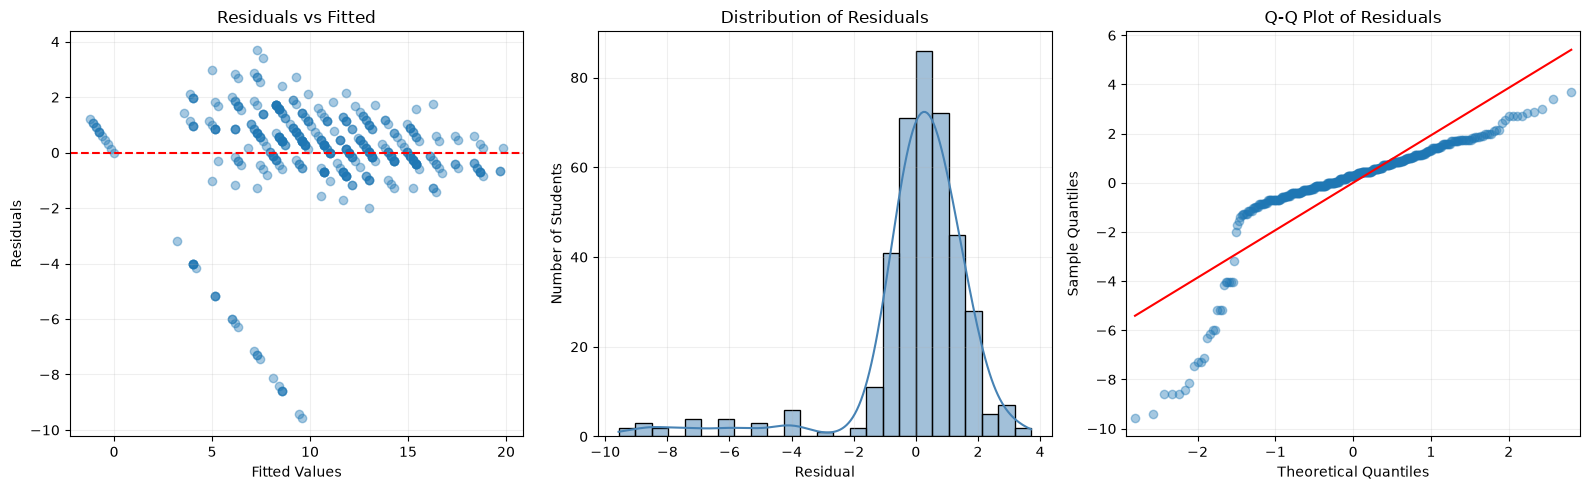

In [15]:
import statsmodels.api as sm

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].scatter(fitted_values, residuals, alpha=0.4)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Residuals vs Fitted")
axes[0].set_xlabel("Fitted Values")
axes[0].set_ylabel("Residuals")
axes[0].grid(alpha=0.2)

sns.histplot(residuals, bins=25, kde=True, color="steelblue", ax=axes[1])
axes[1].set_title("Distribution of Residuals")
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Number of Students")
axes[1].grid(alpha=0.2)

sm.qqplot(residuals, line="s", ax=axes[2], alpha=0.4)
axes[2].set_title("Q-Q Plot of Residuals")
axes[2].grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Students with a Final Grade of Zero

38 students have G3 = 0. They were not flagged in Section 4 because the IQR lower bound for G3 is -1, and a grade cannot be below that.

The next cell checks how much of the large negative residuals comes from these students. The model is then refitted without them as a sensitivity check only: all 395 records remain in the main analysis.

In [16]:
zero_final = df_clean["G3"] == 0

print("=== STUDENTS WITH G3 = 0 ===")
print("Students:", zero_final.sum())
print("With G2 above 0:", (zero_final & (df_clean["G2"] > 0)).sum())
print("With 0 absences:", (zero_final & (df_clean["absences"] == 0)).sum())
print("Residuals below -4:", (residuals < -4).sum())
print("Residuals below -4 with G3 = 0:", ((residuals < -4) & zero_final).sum())

sensitivity_model = smf.ols("G3 ~ G1 + G2", data=df_clean[~zero_final]).fit()
sensitivity_residuals = sensitivity_model.resid

sensitivity = pd.DataFrame({
    "All students": {
        "Observations": multiple_model.nobs,
        "R-squared": multiple_model.rsquared,
        "MAE": residuals.abs().mean(),
        "RMSE": np.sqrt((residuals ** 2).mean()),
        "Residual skewness": residuals.skew()
    },
    "Without G3 = 0": {
        "Observations": sensitivity_model.nobs,
        "R-squared": sensitivity_model.rsquared,
        "MAE": sensitivity_residuals.abs().mean(),
        "RMSE": np.sqrt((sensitivity_residuals ** 2).mean()),
        "Residual skewness": sensitivity_residuals.skew()
    }
})

display(sensitivity.round(4))

=== STUDENTS WITH G3 = 0 ===
Students: 38
With G2 above 0: 25
With 0 absences: 38
Residuals below -4: 24
Residuals below -4 with G3 = 0: 24


,All students,Without G3 = 0
Observations,395.0000,357.0000
R-squared,0.8222,0.9347
MAE,1.1375,0.6280
RMSE,1.9296,0.8237
Residual skewness,-2.6538,0.1436


### Interpretation of Residual Analysis

The mean of the residuals is practically zero, with a standard deviation of 1.932. On average the model is off by MAE = 1.138 points, and RMSE = 1.930.

Most residuals are small, but they are not evenly distributed. The Residuals vs Fitted plot shows a separate diagonal band of large negative errors, with a minimum of -9.57. The histogram has a long left tail (skewness = -2.65), and the Q-Q plot departs from the reference line in the tails. The normality assumption is therefore not fully satisfied, and the p-values should be read with caution.

The cause can be identified. All 24 residuals below -4 belong to students with G3 = 0. Of the 38 students with G3 = 0, 25 had a G2 above 0, and all 38 have 0 absences. This suggests that many of them did not take the final assessment, rather than earning a real zero. The dataset does not state this, so it remains a likely explanation and not a confirmed fact.

Without these students, R² rises from 0.8222 to 0.9347, RMSE falls from 1.930 to 0.824 and the skewness falls to 0.14. A straight line therefore describes students who received a final grade very well, and the main weakness of the model is the group with G3 = 0. These records remain in the main analysis because they are valid values, and removing them would make the model look better than it is.